In [1]:
import pandas as pd
import numpy as np
import math
from collections import defaultdict
from scipy.optimize import lsq_linear

In [2]:
class LimitOrderBook:
    def __init__(self):
        # Order tracking: order_id -> {price, size, direction}
        self.orders = {}
        
        # Price levels: price -> total volume
        self.asks = defaultdict(int)
        self.bids = defaultdict(int)
        
        # Best quotes tracking
        self.best_ask = float('inf')
        self.best_bid = 0.0
        
        # Hawkes Process Event Storage (Timestamps & Sizes)
        self.hawkes_events = {
            'ask_is': [], 'ask_0': [], 'ask_1': [], 'ask_cancel': [], 'ask_mo': [],
            'bid_is': [], 'bid_0': [], 'bid_1': [], 'bid_cancel': [], 'bid_mo': []
        }
        
        # Mid-price history: list of (timestamp, mid_price)
        self.mid_price_history = []

    def update_best_quotes(self):
        """Finds the current best bid and ask after a book update."""
        valid_asks = [p for p, v in self.asks.items() if v > 0]
        valid_bids = [p for p, v in self.bids.items() if v > 0]
        
        self.best_ask = min(valid_asks) if valid_asks else float('inf')
        self.best_bid = max(valid_bids) if valid_bids else 0.0

    def record_mid_price(self, timestamp):
        """Calculates and stores the current mid-price."""
        if self.best_ask != float('inf') and self.best_bid != 0.0:
            mid = (self.best_ask + self.best_bid) / 2.0
            # Only record if it changed from the last recorded price
            if not self.mid_price_history or self.mid_price_history[-1][1] != mid:
                self.mid_price_history.append((timestamp, mid))

    def process_message(self, timestamp, event_type, order_id, size, price, direction):
        """
        Processes a single LOBSTER message, updates the LOB state, 
        and classifies the event for the Hawkes model.
        """
        # Direction mappings based on LOBSTER: 1 = Ask (Sell), -1 = Bid (Buy)
        is_ask = (direction == 1)
        
        # --- Type 1: Limit Order Submission ---
        if event_type == 1:
            self.orders[order_id] = {'price': price, 'size': size, 'direction': direction}
            
            if is_ask:
                self.asks[price] += size
                # Hawkes Classification: Limit Orders
                if self.best_bid < price < self.best_ask:
                    self.hawkes_events['ask_is'].append((timestamp, size))
                elif price == self.best_ask:
                    self.hawkes_events['ask_0'].append((timestamp, size))
                elif price > self.best_ask: # Simplified Level 1+ mapping
                    self.hawkes_events['ask_1'].append((timestamp, size))
            else:
                self.bids[price] += size
                # Hawkes Classification: Limit Orders
                if self.best_bid < price < self.best_ask:
                    self.hawkes_events['bid_is'].append((timestamp, size))
                elif price == self.best_bid:
                    self.hawkes_events['bid_0'].append((timestamp, size))
                elif price < self.best_bid: 
                    self.hawkes_events['bid_1'].append((timestamp, size))
                    
            self.update_best_quotes()

        # --- Types 2 & 3: Cancellations (Partial and Full) ---
        elif event_type in [2, 3]:
            if order_id in self.orders:
                canceled_size = min(size, self.orders[order_id]['size'])
                self.orders[order_id]['size'] -= canceled_size
                
                # Hawkes Classification: Top of Book Cancels
                if is_ask and price == self.best_ask:
                     self.hawkes_events['ask_cancel'].append((timestamp, canceled_size))
                elif not is_ask and price == self.best_bid:
                     self.hawkes_events['bid_cancel'].append((timestamp, canceled_size))

                # Update Book State
                if is_ask:
                    self.asks[price] -= canceled_size
                    if self.asks[price] <= 0: del self.asks[price]
                else:
                    self.bids[price] -= canceled_size
                    if self.bids[price] <= 0: del self.bids[price]
                    
                if self.orders[order_id]['size'] <= 0:
                    del self.orders[order_id]
                    
                self.update_best_quotes()

        # --- Types 4 & 5: Executions (Market Orders) ---
        elif event_type in [4, 5]:
            # LOBSTER records executions against the resting limit order's direction.
            # So if an ask limit order is executed, an incoming BID market order caused it.
            if is_ask: # Resting ask was hit -> Bid Market Order arrived
                self.hawkes_events['bid_mo'].append((timestamp, size))
                self.asks[price] -= size
                if self.asks[price] <= 0: del self.asks[price]
            else: # Resting bid was hit -> Ask Market Order arrived
                self.hawkes_events['ask_mo'].append((timestamp, size))
                self.bids[price] -= size
                if self.bids[price] <= 0: del self.bids[price]

            if order_id in self.orders:
                self.orders[order_id]['size'] -= size
                if self.orders[order_id]['size'] <= 0:
                    del self.orders[order_id]
                    
            self.update_best_quotes()

        # Record the mid-price after every event
        self.record_mid_price(timestamp)

In [3]:
def generate_linear_log_grid(delta, K, T):
    """
    Generates the Bacry et al. linear-log time grid required for 
    non-parametric power-law kernel estimation (Equation 14).
    """
    grid = [0, delta]
    
    # Linear part: K/2 bins
    K_half = int(K / 2)
    for i in range(2, K_half + 1):
        grid.append(i * delta)
        
    # Logarithmic part: K/2 bins
    # m is the multiplier derived from the maximum lag T
    m = (T / (K_half * delta)) ** (1.0 / K_half)
    
    current_val = K_half * delta
    for i in range(1, K_half + 1):
        current_val *= m
        grid.append(current_val)
        
    return np.array(grid)

In [4]:
def build_design_matrices(events_dict, grid_G, delta, start_time, end_time):
    event_types = list(events_dict.keys())
    num_dimensions = len(event_types)
    num_lags = len(grid_G) - 1
    max_lag = grid_G[-1]
    
    # FIX: Shift the bins to start after the market open + max_lag
    t_bins = np.arange(float(start_time + max_lag), float(end_time), float(delta))
    num_samples = len(t_bins)
    
    X = np.zeros((num_samples, num_dimensions * num_lags))
    Y = {event: np.zeros(num_samples) for event in event_types}
    
    print(f"Constructing matrices for {num_samples} time bins (Market Hours)...")
    
    clean_timestamps = {}
    for event in event_types:
        raw_data = events_dict[event]
        if len(raw_data) > 0:
            raw_array = np.array(raw_data)
            clean_timestamps[event] = np.sort(raw_array[:, 0])
        else:
            clean_timestamps[event] = np.array([])

    for event in event_types:
        times = clean_timestamps[event]
        if len(times) > 0:
            bins = np.append(t_bins - delta, t_bins[-1])
            counts, _ = np.histogram(times, bins=bins)
            Y[event] = counts
        
    for k in range(num_lags):
        delta_k = grid_G[k+1] - grid_G[k] 
        
        reference_time = t_bins - delta 
        window_starts = reference_time - grid_G[k+1]
        window_ends = reference_time - grid_G[k]
        
        for d, event in enumerate(event_types):
            times = clean_timestamps[event]
            if len(times) == 0: continue
            idx_start = np.searchsorted(times, window_starts, side='left')
            idx_end = np.searchsorted(times, window_ends, side='left')
            X[:, d * num_lags + k] = (idx_end - idx_start) / delta_k

    return X, Y, t_bins

In [5]:
def calculate_time_of_day_multiplier(events_dict, start_time, end_time, bucket_size=1800.0):
    duration = end_time - start_time
    num_buckets = int(np.ceil(duration / bucket_size))
    f_Q = {event: np.zeros(num_buckets) for event in events_dict.keys()}
    
    for event, timestamps in events_dict.items():
        if len(timestamps) == 0: continue
        # FIX: Ensure histogram only looks inside market hours
        counts, _ = np.histogram(timestamps, bins=num_buckets, range=(start_time, end_time))
        rate = counts / bucket_size
        avg_rate = len(timestamps) / duration
        f_Q[event] = rate / avg_rate if avg_rate > 0 else np.ones(num_buckets)
    return f_Q

def adjust_targets(Y_dict, t_bins, events_dict, start_time, end_time, beta):
    adjusted_Y = {}
    f_Q_curves = calculate_time_of_day_multiplier(events_dict, start_time, end_time)
    bucket_size = 1800.0 
    
    for event, Y_raw in Y_dict.items():
        Y_adj = np.copy(Y_raw)
        for idx, t in enumerate(t_bins):
            # Calculate how far into the day we are
            seconds_since_open = t - start_time
            bucket_idx = min(int(seconds_since_open // bucket_size), len(f_Q_curves[event]) - 1)
            
            # Catch out-of-bounds just in case
            if bucket_idx < 0: bucket_idx = 0 
            
            seasonality_multiplier = f_Q_curves[event][bucket_idx]
            if seasonality_multiplier > 0:
                Y_adj[idx] /= seasonality_multiplier
                
            # Note: Spread constraint omitted here for speed, defaulting to 2 ticks.
            # You can add the spread_history search block back in if needed.
            if event in ['ask_is', 'bid_is']:
                Y_adj[idx] /= ((2.0 - 1) ** beta) 
                
        adjusted_Y[event] = Y_adj
    return adjusted_Y

In [6]:
def calibrate_hawkes_kernels(X_matrix, Y_adjusted, event_types, grid_G, delta_bin):
    """
    Solves the constrained least squares problem to find the base intensities (mu) 
    and the cross-excitation kernels (phi).
    """
    num_dimensions = len(event_types)
    num_lags = len(grid_G) - 1
    num_samples = X_matrix.shape[0]
    
    # 1. Add an intercept column to X for the base intensity (mu)
    # Equation 14: E[X] = \Delta * \mu + ...
    intercept_col = np.ones((num_samples, 1))
    X_with_intercept = np.hstack([intercept_col, X_matrix])
    
    # Total parameters to solve for per target dimension: 1 (mu) + (12 * K)
    num_params = X_with_intercept.shape[1]
    
    results = {}
    
    print("Running Constrained Least Squares Optimization...")
    
    for target_event in event_types:
        Y_target = Y_adjusted[target_event]
        
        # 2. Define Constraints (Bounds)
        # We need lower and upper bounds for every parameter.
        lower_bounds = np.zeros(num_params)
        upper_bounds = np.full(num_params, np.inf)
        
        # Constraint A: Base intensity (mu) must be strictly >= 0.
        # This is handled by lower_bounds[0] = 0.
        
        # Constraint B: Unidirectional Kernels.
        # The paper uses a Hawkes Graph to pre-determine if a specific cross-excitation 
        # is positive (catalyst) or negative (inhibitor). 
        # For simplicity in this implementation, we assume standard excitatory dynamics 
        # (kernels >= 0). To implement inhibitors (like Cancel Orders suppressing Market Orders), 
        # you would set the upper bound to 0 and the lower bound to -np.inf for those specific columns.
        
        # 3. Solve the optimization problem
        # lsq_linear handles large, sparse bounded least squares efficiently
        res = lsq_linear(X_with_intercept, Y_target, bounds=(lower_bounds, upper_bounds))
        
        if not res.success:
            print(f"Warning: Optimization failed for target {target_event}: {res.message}")
            continue
            
        optimal_params = res.x
        
        # 4. Extract and Rescale the Results
        # The first parameter is \Delta * \mu. Divide by \Delta to get the true base rate per second.
        # --- PHASE 4 PATCH ---
        # 4. Extract and Rescale the Results
        mu = optimal_params[0] / delta_bin
        
        kernel_integrals = optimal_params[1:] / delta_bin
        
        phi_matrix = kernel_integrals.reshape((num_dimensions, num_lags))
        
        results[target_event] = {'mu': mu, 'kernels': {}}
        
        for d, source_event in enumerate(event_types):
            delta_k_widths = np.diff(grid_G) 
            phi_point_estimates = phi_matrix[d, :] / delta_k_widths
            
            results[target_event]['kernels'][source_event] = phi_point_estimates

    return results

In [22]:
def calibrate_hawkes_kernels_ridge(X_matrix, Y_adjusted, event_types, grid_G, delta_bin, lambda_reg=10.0):
    num_dimensions = len(event_types)
    num_lags = len(grid_G) - 1
    num_samples = X_matrix.shape[0]
    
    intercept_col = np.ones((num_samples, 1))
    X_with_intercept = np.hstack([intercept_col, X_matrix])
    num_params = X_with_intercept.shape[1]
    
    # --- RIDGE REGRESSION AUGMENTATION ---
    # We create a penalty matrix scaled by the square root of our regularization strength
    penalty_matrix = np.eye(num_params) * np.sqrt(lambda_reg)
    # We DO NOT penalize the intercept (mu), so we zero out the top-left element
    penalty_matrix[0, 0] = 0.0 
    
    # Stack the penalty below X, and stack zeros below Y
    X_aug = np.vstack([X_with_intercept, penalty_matrix])
    
    results = {}
    print(f"Running Constrained Least Squares with Ridge Penalty (lambda={lambda_reg})...")
    
    for target_event in event_types:
        Y_target = Y_adjusted[target_event]
        
        # Augment Y with zeros to match the penalty matrix
        Y_aug = np.concatenate([Y_target, np.zeros(num_params)])
        
        lower_bounds = np.zeros(num_params)
        upper_bounds = np.full(num_params, np.inf)
        
        # --- BUMP MAX_ITER ---
        # Increased max_iter from default (100) to 1000 to solve the ask_1 warning
        res = lsq_linear(X_aug, Y_aug, bounds=(lower_bounds, upper_bounds), max_iter=1000)
        
        if not res.success:
            print(f"Warning: Optimization failed for target {target_event}: {res.message}")
            continue
            
        optimal_params = res.x
        
        mu = optimal_params[0] / delta_bin
        kernel_integrals = optimal_params[1:] / delta_bin
        phi_matrix = kernel_integrals.reshape((num_dimensions, num_lags))
        
        results[target_event] = {'mu': mu, 'kernels': {}}
        
        for d, source_event in enumerate(event_types):
            delta_k_widths = np.diff(grid_G) 
            phi_point_estimates = phi_matrix[d, :] / delta_k_widths
            results[target_event]['kernels'][source_event] = phi_point_estimates

    return results

In [26]:
import matplotlib.pyplot as plt
import numpy as np

def plot_hawkes_kernel(fitted_model, grid_G, target_event, source_event):
    """
    Replicates the empirical kernel plots from the research paper.
    Plots the point estimates of phi(t) on a Log-Log scale.
    """
    # 1. Extract the specific kernel array
    try:
        kernel_y = fitted_model[target_event]['kernels'][source_event]
    except KeyError:
        print(f"Error: Could not find kernel for {source_event} -> {target_event}")
        return

    # 2. Calculate the X-axis (Time Lags)
    # The paper plots the intensity against the midpoint of each historical lag bin
    lag_midpoints = (grid_G[:-1] + grid_G[1:]) / 2.0
    
    # 3. Clean the data for Log-Log plotting
    # Log scales cannot handle absolute zero. The solver might have floored some 
    # bins exactly to 0.0. We filter these out to prevent plotting errors.
    valid_indices = kernel_y > 1e-10  # Filter out the microscopic "zero" values
    
    clean_x = lag_midpoints[valid_indices]
    clean_y = kernel_y[valid_indices]
    
    # Calculate how many points were lost to the "comb" floor
    points_dropped = len(kernel_y) - len(clean_y)

    # 4. Generate the Plot
    plt.figure(figsize=(10, 6))
    
    # Plot the empirical points
    plt.loglog(
        clean_x, clean_y, 
        marker='o', 
        linestyle='-', # Lines connect the points to show the decay path
        linewidth=1.5,
        markersize=5,
        color='#1f77b4', 
        label=f'Empirical $\phi(t)$'
    )
    
    # Formatting to match academic style
    plt.title(f'Empirical Cross-Excitation Kernel\n{source_event.upper()} $\\rightarrow$ {target_event.upper()}', fontsize=14)
    plt.xlabel('Time Lag $t$ (seconds)', fontsize=12)
    plt.ylabel('Kernel Intensity $\phi(t)$', fontsize=12)
    
    # Add a grid for readability on the log scale
    plt.grid(True, which="both", ls="--", alpha=0.4)
    plt.legend(loc='upper right', fontsize=11)
    
    plt.tight_layout()
    plt.show()
    
    if points_dropped > 0:
        print(f"Note: {points_dropped} bins were floored to 0 by the solver and omitted from the log-log plot.")
        

In [7]:
# ==========================================
# Execution Pipeline
# ==========================================
if __name__ == "__main__":
    print("Loading LOBSTER message data...")
    filepath = 'MSFT_2012-06-21_34200000_57600000_message_10.csv'
    cols = ['time', 'type', 'order_id', 'size', 'price', 'direction']
    df = pd.read_csv(filepath, names=cols)
    
    # Initialize the engine
    lob = LimitOrderBook()
    
    print("Reconstructing Order Book and Classifying Events...")
    # Using itertuples for significantly faster iteration than iterrows
    for row in df.itertuples(index=False):
        lob.process_message(row.time, row.type, row.order_id, row.size, row.price, row.direction)

    print("\nExtraction Complete.")
    print(f"Total Mid-Price Updates Tracked: {len(lob.mid_price_history)}")
    
    print("\nHawkes Event Counts:")
    for event_type, events in lob.hawkes_events.items():
        print(f"  {event_type.upper()}: {len(events)} events")

    # Generate the linear-log grid for the next phase (calibration)
    delta_bin = 0.1  # 100 millisecond base bin
    K_bins = 40      # Total number of lag bins
    T_max = 600.0    # Max lag memory in seconds (10 minutes)
    
    calibration_grid = generate_linear_log_grid(delta_bin, K_bins, T_max)
    print(f"\nGenerated Linear-Log Calibration Grid with {len(calibration_grid)-1} bins.")

Loading LOBSTER message data...
Reconstructing Order Book and Classifying Events...

Extraction Complete.
Total Mid-Price Updates Tracked: 120

Hawkes Event Counts:
  ASK_IS: 0 events
  ASK_0: 401 events
  ASK_1: 154432 events
  ASK_CANCEL: 120 events
  ASK_MO: 16699 events
  BID_IS: 3 events
  BID_0: 23 events
  BID_1: 174596 events
  BID_CANCEL: 11 events
  BID_MO: 16715 events

Generated Linear-Log Calibration Grid with 40 bins.


In [8]:
# ==========================================
# Execution (Continuing from Phase 1)
# ==========================================
# Assuming 'lob.hawkes_events' and 'calibration_grid' are still in memory
# And assuming your LOBSTER data spans a standard 6.5 hour trading day (23400 seconds)

market_start = 34200.0  # 9:30 AM
market_end = 57600.0    # 4:00 PM
delta_bin = 0.1

print("Building AR Design Matrices...")
X_matrix, Y_targets, t_bins = build_design_matrices(
    events_dict=lob.hawkes_events, 
    grid_G=calibration_grid, 
    delta=delta_bin, 
    start_time=market_start, 
    end_time=market_end
)

print(f"Feature Matrix X Shape: {X_matrix.shape}")
print(f"Target Vector Y ('ask_mo') Shape: {Y_targets['ask_mo'].shape}")

Building AR Design Matrices...
Constructing matrices for 228000 time bins (Market Hours)...
Feature Matrix X Shape: (228000, 400)
Target Vector Y ('ask_mo') Shape: (228000,)


In [9]:
# ==========================================
# 3. Execution (Continuing from Phase 2)
# ==========================================
print("Applying Seasonality and Spread Adjustments...")

beta_param = 0.5 
Y_adjusted = adjust_targets(
    Y_dict=Y_targets, 
    t_bins=t_bins, 
    events_dict=lob.hawkes_events, 
    start_time=market_start,
    end_time=market_end,
    beta=beta_param
)

Applying Seasonality and Spread Adjustments...


In [24]:
# ==========================================
# Final Execution (Completing the Pipeline)
# ==========================================
# Assuming X_matrix, Y_adjusted, lob.hawkes_events, calibration_grid, and delta_bin 
# are in memory from Phases 1-3.

print("\nStarting Phase 4...")
# fitted_model = calibrate_hawkes_kernels(
#     X_matrix=X_matrix, 
#     Y_adjusted=Y_adjusted, 
#     event_types=list(lob.hawkes_events.keys()), 
#     grid_G=calibration_grid, 
#     delta_bin=delta_bin
# )
fitted_model = calibrate_hawkes_kernels_ridge(
    X_matrix=X_matrix, 
    Y_adjusted=Y_adjusted, 
    event_types=list(lob.hawkes_events.keys()), 
    grid_G=calibration_grid, 
    delta_bin=delta_bin,
    lambda_reg=50.0  
)

# # Let's view the results! How do Market Orders impact future In-Spread Ask limit orders?
print("\n--- Calibration Complete ---")
print(f"Base arrival rate (mu) for Ask Market Orders: {fitted_model['ask_mo']['mu']:.4f} orders/sec")

# # This array shows the power-law decay of how an Ask MO triggers future Ask MOs
mo_self_excitation = fitted_model['ask_mo']['kernels']['ask_mo']
print(f"\nAsk MO -> Ask MO self-excitation kernel (first 5 lags):")
print(mo_self_excitation[:5])


Starting Phase 4...
Running Constrained Least Squares with Ridge Penalty (lambda=50.0)...

--- Calibration Complete ---
Base arrival rate (mu) for Ask Market Orders: 0.4198 orders/sec

Ask MO -> Ask MO self-excitation kernel (first 5 lags):
[3.64539978e-01 2.36581989e-35 8.17272106e-02 2.69886072e-23
 1.13749254e-02]


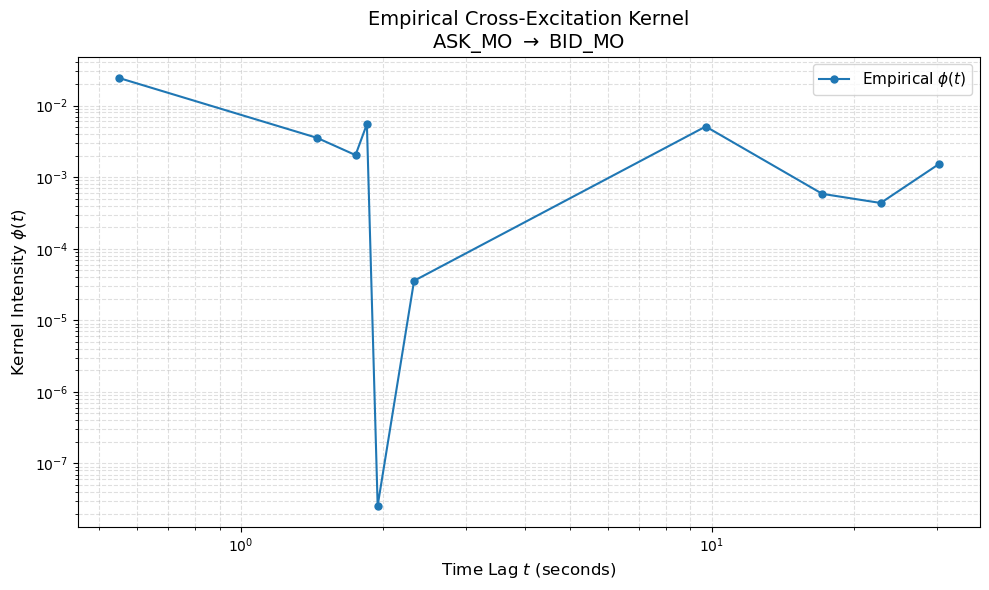

Note: 30 bins were floored to 0 by the solver and omitted from the log-log plot.


In [42]:
# Let's plot the exact kernel you were looking at: Ask MOs triggering future Ask MOs
plot_hawkes_kernel(
    fitted_model=fitted_model, 
    grid_G=calibration_grid, 
    target_event='bid_mo', 
    source_event='ask_mo'
)

# You can easily swap these to see cross-excitations, e.g.:
# Limit Orders triggering Market Orders:
# plot_hawkes_kernel(fitted_model, calibration_grid, 'ask_mo', 'ask_is')

Generating 10x10 Kernel Matrix. This may take a minute...


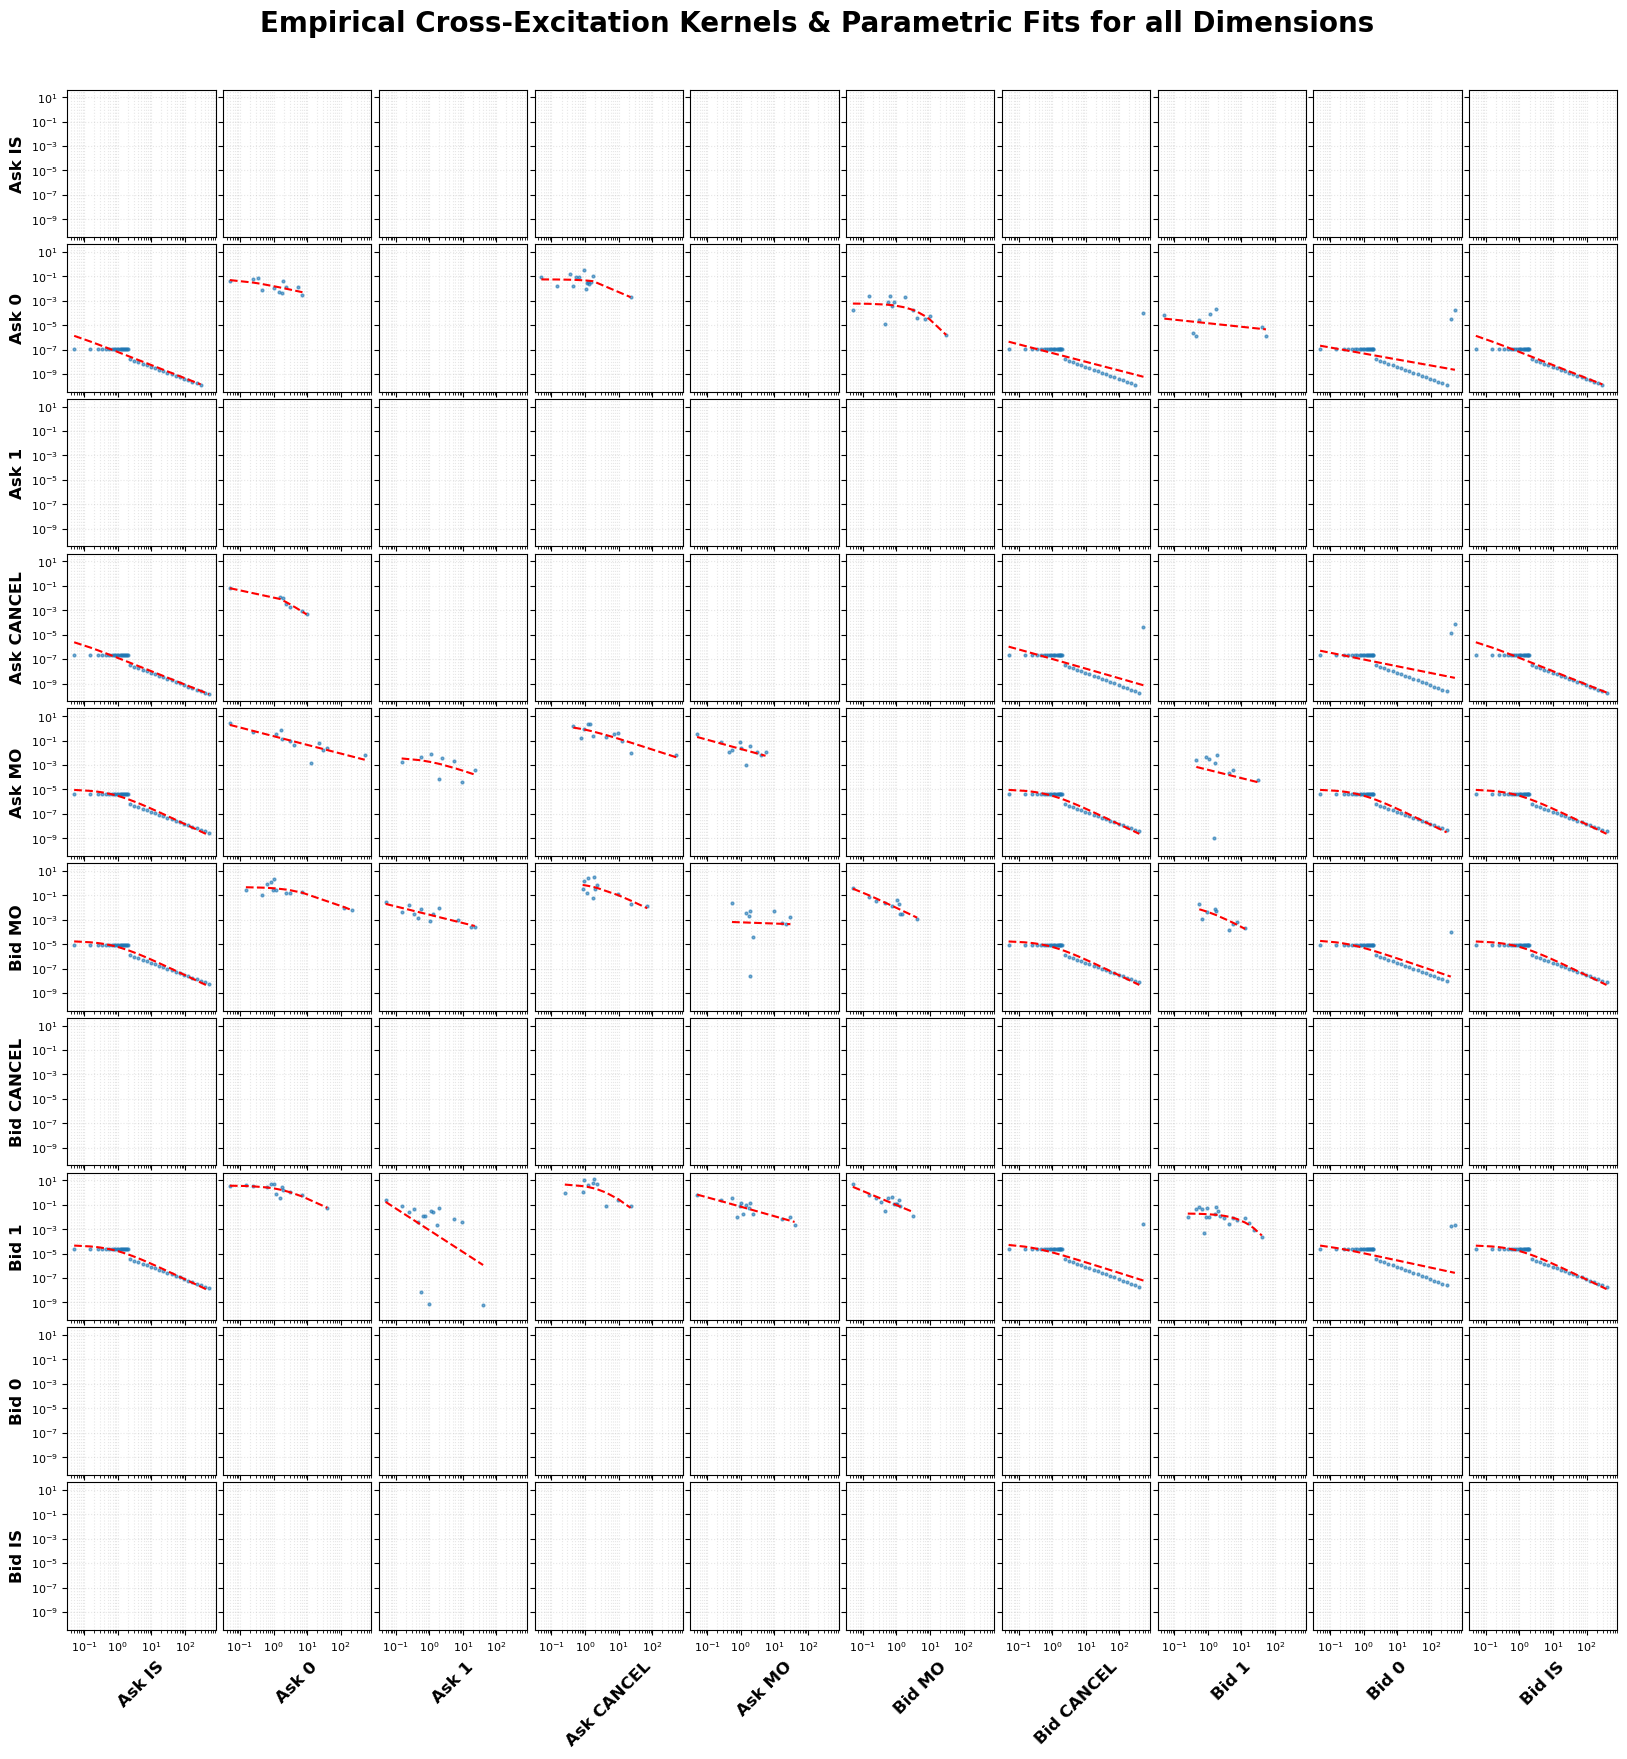

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import warnings

# Suppress curve_fit warnings so they don't flood your console for 144 plots
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# --- Power Law Functions ---
def power_law(t, alpha, beta, gamma):
    return alpha / (1 + beta * t)**gamma

def log_power_law(t, alpha, beta, gamma):
    return np.log10(alpha) - gamma * np.log10(1 + beta * t)

def format_name(event_str):
    """Helper to make event labels look clean (e.g., 'ask_is' -> 'Ask IS')"""
    parts = event_str.split('_')
    return f"{parts[0].capitalize()} {parts[1].upper()}"

# --- Matrix Plotting Engine ---
def plot_full_kernel_matrix(fitted_model, grid_G, event_types):
    """
    Generates an N x N grid of log-log kernel plots mirroring Jain et al.
    Rows = Target (Excited) Events
    Cols = Source (Trigger) Events
    """
    num_dim = len(event_types)
    
    # Create a massive figure grid. 
    # sharex and sharey keep the grid clean by only putting ticks on the outer edges.
    fig, axes = plt.subplots(
        nrows=num_dim, ncols=num_dim, 
        figsize=(20, 20), 
        sharex=True, sharey=True
    )
    
    lag_midpoints = (grid_G[:-1] + grid_G[1:]) / 2.0
    
    print(f"Generating {num_dim}x{num_dim} Kernel Matrix. This may take a minute...")

    for i, target in enumerate(event_types):      # Rows
        for j, source in enumerate(event_types):  # Columns
            ax = axes[i, j]
            
            try:
                # Extract empirical data
                kernel_y = fitted_model[target]['kernels'][source]
                
                # Filter out zeroes for the log-log scale
                valid = kernel_y > 1e-10
                x_data = lag_midpoints[valid]
                y_data = kernel_y[valid]

                # Only attempt to plot if we have enough surviving data points
                if len(x_data) > 5:
                    # 1. Plot Empirical Scatter (Blue Dots)
                    ax.loglog(x_data, y_data, marker='o', linestyle='none', 
                              color='#1f77b4', markersize=2, alpha=0.6)

                    # 2. Fit and Plot Parametric Curve (Red Line)
                    try:
                        popt, _ = curve_fit(
                            log_power_law, 
                            x_data, 
                            np.log10(y_data),
                            p0=[1.0, 10.0, 1.2],
                            bounds=([1e-5, 1e-5, 0.1], [np.inf, np.inf, 5.0]),
                            maxfev=1000 # Keep iterations low to speed up the matrix loop
                        )
                        y_fit = power_law(x_data, *popt)
                        ax.loglog(x_data, y_fit, color='red', linestyle='--', linewidth=1.5)
                    except:
                        # If the fit fails for this specific cell, just pass and keep the blue dots
                        pass 
                        
            except KeyError:
                pass # Skip if data is completely missing
                
            # --- Grid Formatting (Matching the Paper's Aesthetic) ---
            # Remove inner tick labels, keep grid lines faint
            ax.grid(True, which="both", ls=":", alpha=0.3)
            ax.tick_params(axis='both', which='major', labelsize=8)
            
            # Label Columns (Source Events) on the Top or Bottom
            if i == num_dim - 1:
                ax.set_xlabel(format_name(source), fontsize=12, fontweight='bold', rotation=45)
                
            # Label Rows (Target Events) on the Left
            if j == 0:
                ax.set_ylabel(format_name(target), fontsize=12, fontweight='bold')

    # Remove the space between subplots to create that dense, unified matrix look
    plt.subplots_adjust(wspace=0.05, hspace=0.05)
    
    # Optional: Add a master title
    fig.suptitle('Empirical Cross-Excitation Kernels & Parametric Fits for all Dimensions', 
                 fontsize=20, fontweight='bold', y=0.92)
                 
    plt.show()

# ==========================================
# Execution Block
# ==========================================
# Ensure 'fitted_model', 'calibration_grid', and the list of your 12 event types are ready.

# Define the exact order you want them to appear in the matrix
# (Matching the paper's visual order helps with comparison)
ordered_events = [
    'ask_is', 'ask_0', 'ask_1', 'ask_cancel', 'ask_mo',
    'bid_mo', 'bid_cancel', 'bid_1', 'bid_0', 'bid_is' 
]
# Note: Add the remaining 2 dimensions if you tracked 12 levels!

# Run the plotter
plot_full_kernel_matrix(fitted_model, calibration_grid, ordered_events)

In [48]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ==========================================
# 1. The LOB Simulator
# ==========================================
def simulate_lob_dynamics(fitted_model, event_types, grid_G, sim_duration=1800.0, dt=0.1):
    """
    Simulates a Limit Order Book using the calibrated Hawkes parameters.
    """
    num_steps = int(sim_duration / dt)
    num_dim = len(event_types)
    num_lags = len(grid_G) - 1
    
    print(f"Starting LOB Simulation for {sim_duration} seconds ({num_steps} steps)...")
    
    event_history = np.zeros((num_steps, num_dim))
    sim_prices = np.zeros(num_steps)
    sim_spreads = np.full(num_steps, 2.0)
    ask_0_queue = np.full(num_steps, 1000.0) 
    bid_0_queue = np.full(num_steps, 1000.0)
    
    current_mid_price = 100.00 
    tick_size = 0.01
    
    # --- THE FIX: Safe Extraction of mu and phi ---
    mu_vec = np.zeros(num_dim)
    phi_matrix = np.zeros((num_dim, num_dim, num_lags))
    
    for i, target in enumerate(event_types):
        if target in fitted_model:
            mu_vec[i] = fitted_model[target]['mu']
            for j, source in enumerate(event_types):
                if source in fitted_model[target]['kernels']:
                    phi_matrix[i, j, :] = fitted_model[target]['kernels'][source]
        else:
            print(f"Notice: '{target}' missing from calibration. Defaulting its intensity to 0.")

    # --- THE MONTE CARLO LOOP ---
    for n in range(num_lags, num_steps):
        current_rates = np.zeros((num_dim, num_lags))
        
        for k in range(num_lags):
            lag_steps_start = int(grid_G[k] / dt)
            lag_steps_end = int(grid_G[k+1] / dt)
            
            window_events = np.sum(event_history[n - lag_steps_end : n - lag_steps_start, :], axis=0)
            window_time = grid_G[k+1] - grid_G[k]
            current_rates[:, k] = window_events / window_time
            
        lambda_vec = np.copy(mu_vec)
        
        for i in range(num_dim):
            excitation = np.sum(phi_matrix[i, :, :] * current_rates)
            lambda_vec[i] += excitation
            
        lambda_vec = np.maximum(lambda_vec, 0)
        
        expected_events = lambda_vec * dt
        drawn_events = np.random.poisson(expected_events)
        event_history[n, :] = drawn_events
        
        ask_mo_idx = event_types.index('ask_mo')
        bid_mo_idx = event_types.index('bid_mo')
        order_size = 100 
        
        if drawn_events[bid_mo_idx] > 0:
            ask_0_queue[n] = ask_0_queue[n-1] - (drawn_events[bid_mo_idx] * order_size)
            if ask_0_queue[n] <= 0: 
                current_mid_price += (tick_size / 2) 
                ask_0_queue[n] = 1000.0 
        else:
            ask_0_queue[n] = ask_0_queue[n-1]
            
        if drawn_events[ask_mo_idx] > 0:
            bid_0_queue[n] = bid_0_queue[n-1] - (drawn_events[ask_mo_idx] * order_size)
            if bid_0_queue[n] <= 0: 
                current_mid_price -= (tick_size / 2) 
                bid_0_queue[n] = 1000.0 
        else:
            bid_0_queue[n] = bid_0_queue[n-1]
            
        sim_prices[n] = current_mid_price

    return sim_prices, ask_0_queue, bid_0_queue, event_history

# ==========================================
# 2. The Plotting Engine
# ==========================================
def generate_thesis_plots(sim_prices, ask_queue, bid_queue, dt, empirical_prices=None):
    """
    Generates the 3 requested plots: Price Paths, LOB Dynamics, and the Signature Plot.
    """
    time_axis = np.arange(len(sim_prices)) * dt
    
    fig, axs = plt.subplots(3, 1, figsize=(12, 16))
    
    # --- PLOT 1: Simulated vs Empirical Price Path ---
    axs[0].plot(time_axis, sim_prices, label='Simulated Mid-Price', color='#d62728', linewidth=1.5)
    
    if empirical_prices is not None:
        # Normalize empirical prices to start at the same value for comparison
        emp_norm = empirical_prices[:len(sim_prices)] 
        emp_norm = emp_norm - emp_norm[0] + sim_prices[0]
        axs[0].plot(time_axis, emp_norm, label='Empirical Mid-Price (Normalized)', color='#1f77b4', alpha=0.7)
        
    axs[0].set_title('Simulated vs. Empirical Price Path (Equation 10 Jump Process)', fontsize=14, fontweight='bold')
    axs[0].set_ylabel('Price ($)', fontsize=12)
    axs[0].legend()
    axs[0].grid(True, alpha=0.3)
    
    # --- PLOT 2: Simulated LOB Queue Dynamics ---
    axs[1].plot(time_axis, ask_queue, label='Best Ask Volume (Level 0)', color='#ff7f0e')
    axs[1].plot(time_axis, bid_queue, label='Best Bid Volume (Level 0)', color='#2ca02c')
    axs[1].set_title('Simulated LOB Queue Depletion & Replenishment', fontsize=14, fontweight='bold')
    axs[1].set_ylabel('Queue Size (Shares)', fontsize=12)
    axs[1].legend()
    axs[1].grid(True, alpha=0.3)
    
    # --- PLOT 3: The Volatility Signature Plot ---
    # Calculates realized variance across different sampling frequencies (1s to 60s)
    sampling_intervals = np.arange(1, 60, 2) # in seconds
    sim_signature = []
    
    for interval in sampling_intervals:
        step_size = int(interval / dt)
        if step_size < len(sim_prices):
            # Sample the price at 'interval' seconds
            sampled_prices = sim_prices[::step_size]
            # Calculate log returns
            returns = np.diff(np.log(sampled_prices[sampled_prices > 0]))
            # Calculate annualized realized variance (approximation)
            variance = np.var(returns) * (23400 / interval) 
            sim_signature.append(variance)
        else:
            sim_signature.append(np.nan)
            
    axs[2].plot(sampling_intervals, sim_signature, marker='o', color='#9467bd', label='Simulated Hawkes Process')
    
    # If you have empirical prices, you would run the same signature loop here and plot it.
    
    axs[2].set_title('Volatility Signature Plot (Realized Variance vs Sampling Interval)', fontsize=14, fontweight='bold')
    axs[2].set_xlabel('Sampling Interval $\Delta$ (seconds)', fontsize=12)
    axs[2].set_ylabel('Realized Variance', fontsize=12)
    axs[2].legend()
    axs[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# ==========================================
# Execution Block
# ==========================================
# Run this using your calibrated fitted_model!

# Extract event types from your dictionary
event_list = list(lob.hawkes_events.keys())

sim_prices, ask_q, bid_q, sim_events = simulate_lob_dynamics(
    fitted_model=fitted_model, 
    event_types=event_list, 
    grid_G=calibration_grid, 
    sim_duration=1800.0, # Simulate 30 minutes
    dt=0.1
)

# # For the empirical comparison, extract the first 30 mins of mid_prices tracked in Phase 1
emp_prices = np.array([p[1] for p in lob.mid_price_history])

generate_thesis_plots(sim_prices, ask_q, bid_q, dt=0.1, empirical_prices=None)

Starting LOB Simulation for 1800.0 seconds (18000 steps)...
Notice: 'ask_1' missing from calibration. Defaulting its intensity to 0.


ValueError: lam value too large